# Análise de textura em imagens digitais: estatísticas de 1ª e 2ª ordem e GLCM

**Computação Visual — Projeto 2 (Opção 2: Tutorial teoria e prática)**
Universidade Presbiteriana Mackenzie — FCI — Ciência da Computação — Prof. André Kishimoto

**Integrantes do grupo**

| Nome completo | RA |
|---|---|
| Arthur Silva Santana | 10420550 |
| Richard Barbosa Sanches | 10420179 |
| Totti Ferreira Gomes | 10428490 |

---

## Escopo 

Textura estatística em imagens em **escala de cinza**. Ficam de fora: textura colorida, mapeamento de textura em modelos 3D, LBP, filtros de Gabor, redes neurais e segmentação por textura.

---

## Sumário
1. Teoria: o que é textura?
2. Estatísticas de primeira ordem
3. Estatísticas de segunda ordem: a GLCM
4. Medidas de Haralick
5. Prática: dados (patches de textura)
6. Prática: primeira ordem
7. Prática: GLCM manual vs. scikit-image
8. Prática: medidas por classe
9. Prática: efeito da distância e do ângulo
10. Prática: classificação com k-vizinhos mais próximos
11. Conclusões
12. Referências


## Como executar

1. **Python e bibliotecas.** Testado com Python 3.13, NumPy 2.5.3, Matplotlib 3.11.2, scikit-image 0.26.0 e scikit-learn 1.9.1:

   `pip install numpy matplotlib scikit-image scikit-learn jupyter`

2. **Imagens.** O notebook lê quatro imagens Brodatz de uma pasta `brodatz/` que fica **ao lado do arquivo `.ipynb`**:

   ```
   tutorial_textura_glcm.ipynb
   brodatz/
       grass.tiff
       wood_grain.tiff
       Herringbone_weave.tiff
       brick_wall.tiff
   ```

   As imagens vêm do banco USC-SIPI, Volume 1: Textures (referência 7).

3. **Execução.** Rode as células de cima para baixo (*Run All*). A semente aleatória é fixa (42), então os números impressos são os mesmos a cada execução.

## 1. Teoria: o que é textura?

Não existe uma definição única de textura, mas a ideia comum é: textura descreve **como os níveis de cinza variam e se organizam espacialmente** dentro de uma região. Duas regiões podem ter exatamente o mesmo histograma e texturas totalmente diferentes, porque a textura depende da **disposição espacial** dos pixels, e não só de quais valores aparecem.

Exemplos de descrições qualitativas: lisa, rugosa, listrada, granulada, repetitiva, aleatória.

Existem várias famílias de abordagens para descrever textura (estatísticas, estruturais, baseadas em modelos, baseadas em transformadas/filtros). Neste tutorial usamos a **abordagem estatística**, que resume a textura por números calculados a partir da distribuição dos níveis de cinza:

- **1ª ordem:** olha cada pixel isoladamente (histograma). Não captura organização espacial.
- **2ª ordem:** olha **pares de pixels** a uma certa distância e direção. Captura organização espacial. É aqui que entra a GLCM.

## 2. Estatísticas de primeira ordem

Seja $p(i)$ a probabilidade (histograma normalizado) do nível de cinza $i$, com $i = 0,\dots,L-1$:

$$\mu = \sum_i i\,p(i) \qquad \sigma = \sqrt{\sum_i (i-\mu)^2\,p(i)} \qquad H = -\sum_{i:\,p(i)>0} p(i)\log_2 p(i)$$

- **Média** $\mu$: brilho médio da região.
- **Desvio padrão** $\sigma$: dispersão dos tons (relacionado ao contraste global).
- **Entropia** $H$: quão "espalhado/imprevisível" é o histograma.

Neste notebook as três medidas são calculadas **depois da quantização em 32 níveis** ($L = 32$, tons de 0 a 31). A média e o desvio padrão estão, portanto, em níveis quantizados, e a entropia tem no máximo $\log_2 32 = 5$ bits.

**Limitação:** embaralhar os pixels de uma imagem não muda nenhuma dessas medidas, mas destrói a textura (demonstrado na seção 6).

## 3. Estatísticas de segunda ordem: a GLCM

A **matriz de coocorrência de níveis de cinza** (*Gray-Level Co-occurrence Matrix*, GLCM; Haralick et al., 1973) conta com que frequência um pixel com nível $i$ aparece vizinho de um pixel com nível $j$, dado um deslocamento $(d, \theta)$:

$$C_{d,\theta}(i,j) = \#\{(x,y) : I(x,y)=i \ \text{e}\ I(x+\Delta x,\; y+\Delta y)=j\}, \qquad \Delta x = \mathrm{round}(d\cos\theta),\ \ \Delta y = \mathrm{round}(d\sin\theta)$$

Parâmetros:
- **Distância $d$** (em pixels): escala da textura analisada. Aqui: 1, 3 e 5.
- **Ângulo $\theta$**: direção do vizinho. Aqui: 0°, 45°, 90° e 135°.
- **Níveis de cinza $L$**: a matriz tem tamanho $L \times L$. Com 256 níveis ela seria enorme e esparsa; por isso **quantizamos** a imagem. Aqui: $L = 32$.

Duas operações comuns:
- **Simetrização:** soma-se a transposta, $C + C^T$, para que (i, j) e (j, i) contem igual (ignora o sentido do deslocamento).
- **Normalização:** divide-se pela soma, obtendo probabilidades $P(i,j)$ com $\sum P = 1$.

## 4. Medidas de Haralick

A partir de $P(i,j)$ extraímos números que resumem a textura. As cinco usadas aqui:

| Medida | Fórmula | Interpretação |
|---|---|---|
| **Contraste** | $\sum_{i,j} (i-j)^2 P(i,j)$ | Alto quando pares vizinhos têm tons muito diferentes (textura rugosa, bordas fortes). |
| **Dissimilaridade** | $\sum_{i,j} \lvert i-j\rvert\, P(i,j)$ | Como o contraste, mas com peso linear. |
| **Homogeneidade** | $\sum_{i,j} \dfrac{P(i,j)}{1+(i-j)^2}$ | Alta quando os pares estão perto da diagonal (regiões lisas). |
| **Energia** | $\sqrt{\sum_{i,j} P(i,j)^2}$ | Alta quando poucos pares dominam (padrões regulares/repetitivos). |
| **Correlação** | $\sum_{i,j} \dfrac{(i-\mu_i)(j-\mu_j)\,P(i,j)}{\sigma_i\sigma_j}$ | Dependência linear entre o tom de um pixel e o do vizinho. |

No scikit-image, `energy` é a raiz quadrada da soma dos quadrados (e `ASM` é a soma sem a raiz).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage import io
from skimage.feature import graycomatrix, graycoprops
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 110})

# Parâmetros da proposta
LEVELS    = 32
DISTANCES = [1, 3, 5]
ANGLES    = [0, np.pi/4, np.pi/2, 3*np.pi/4]       # 0°, 45°, 90°, 135°
ANGLE_DEG = [0, 45, 90, 135]
PROPS     = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]
PATCH     = 64

## 5. Prática: dados (patches de textura)

Cada imagem é dividida em blocos de 64×64 pixels sem sobreposição (*patches*). Cada patch guarda sua linha na grade, usada na seção 10, e é quantizado em 32 níveis antes de qualquer medida.

classe   arquivo                   original     usado  patches
grama    grass.tiff                 512x512   510x512       56
madeira  wood_grain.tiff            512x512   510x512       56
tecido   Herringbone_weave.tiff     512x512   510x512       56
tijolo   brick_wall.tiff            512x512   510x512       56

Total de patches: 224 | grade por imagem: 7 linhas x 8 colunas


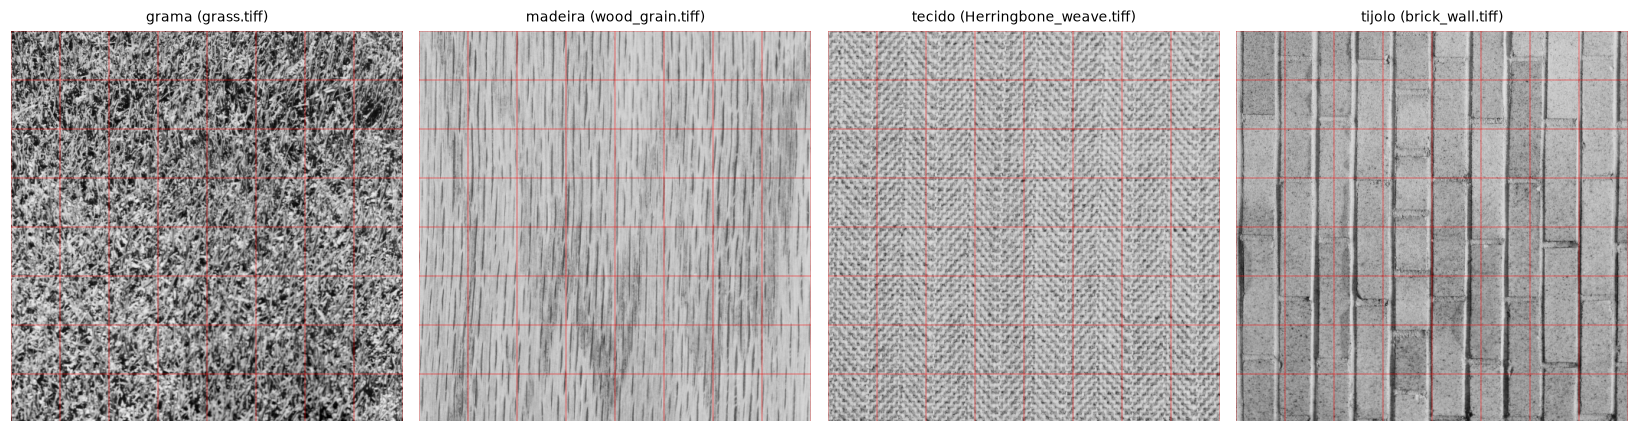

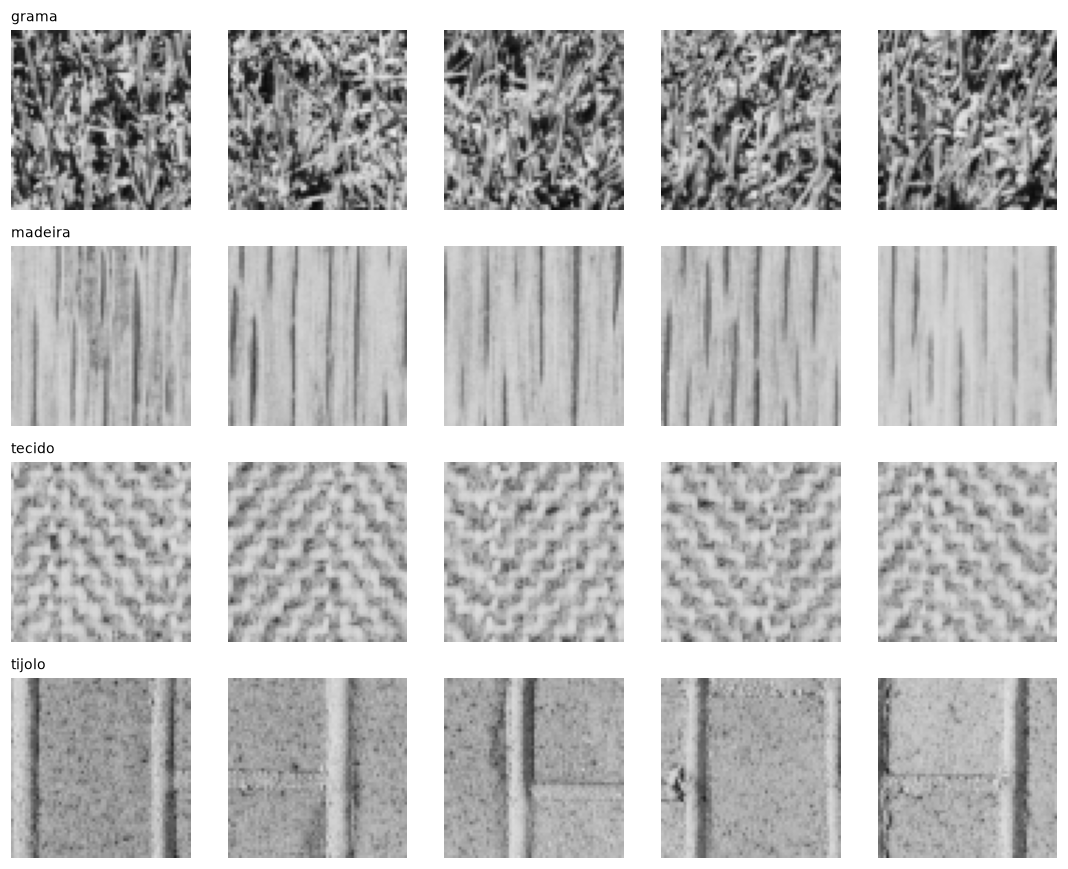

In [2]:
BRODATZ_DIR = "brodatz"
BRODATZ_FILES = {                    # classe -> arquivo dentro de ./brodatz/
    "grama":   "grass.tiff",
    "madeira": "wood_grain.tiff",
    "tecido":  "Herringbone_weave.tiff",
    "tijolo":  "brick_wall.tiff",
}

# Nota da USC-SIPI (Volume 1: Textures): as imagens Brodatz 512x512 têm zeros nas duas últimas linhas.
# Cortamos as linhas/colunas de borda totalmente zeradas.
def trim_zero_border(im):
    rows, cols = np.flatnonzero(im.any(axis=1)), np.flatnonzero(im.any(axis=0))
    return im[rows[0]:rows[-1]+1, cols[0]:cols[-1]+1]

images, original_shape = {}, {}
for classe, arquivo in BRODATZ_FILES.items():
    caminho = os.path.join(BRODATZ_DIR, arquivo)
    if not os.path.exists(caminho):
        raise FileNotFoundError(f"Falta {caminho}. Veja a seção 'Como executar' no início do notebook.")
    im = io.imread(caminho)
    original_shape[classe] = im.shape
    images[classe] = trim_zero_border(im)

def quantize(img, levels=LEVELS):
    return (img.astype(np.int32) * levels // 256).astype(np.uint8)   # tons 0..levels-1

classes = list(images)
patches, labels, prow = [], [], []              # prow: linha do patch na grade
for k, name in enumerate(classes):
    h, w = images[name].shape
    for r in range(0, h - PATCH + 1, PATCH):
        for c in range(0, w - PATCH + 1, PATCH):
            patches.append(images[name][r:r+PATCH, c:c+PATCH]); labels.append(k); prow.append(r // PATCH)
patches, labels, prow = np.array(patches), np.array(labels), np.array(prow)

print(f"{'classe':8s} {'arquivo':24s} {'original':>9s} {'usado':>9s} {'patches':>8s}")
for k, name in enumerate(classes):
    h0, w0 = original_shape[name]; h, w = images[name].shape
    print(f"{name:8s} {BRODATZ_FILES[name]:24s} {str(h0)+'x'+str(w0):>9s} {str(h)+'x'+str(w):>9s} {np.sum(labels == k):8d}")
print(f"\nTotal de patches: {len(patches)} | grade por imagem: {prow.max() + 1} linhas x {w // PATCH} colunas")

# imagens inteiras, com a grade de patches
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for ax, name in zip(axs, classes):
    ax.imshow(images[name], cmap="gray", vmin=0, vmax=255)
    for t in range(0, images[name].shape[0] + 1, PATCH): ax.axhline(t - 0.5, color="red", lw=0.3)
    for t in range(0, images[name].shape[1] + 1, PATCH): ax.axvline(t - 0.5, color="red", lw=0.3)
    ax.set_title(f"{name} ({BRODATZ_FILES[name]})", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

# exemplos de patches (os 5 primeiros de cada classe)
fig, axs = plt.subplots(len(classes), 5, figsize=(10, 2*len(classes)))
for k, name in enumerate(classes):
    for j, i in enumerate(np.where(labels == k)[0][:5]):
        axs[k, j].imshow(patches[i], cmap="gray", vmin=0, vmax=255); axs[k, j].axis("off")
    axs[k, 0].set_title(name, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 6. Prática: primeira ordem

Média, desvio padrão e entropia do histograma de cada patch **já quantizado em 32 níveis**. Demonstração com um patch de tecido: embaralhar os pixels não altera as três medidas.

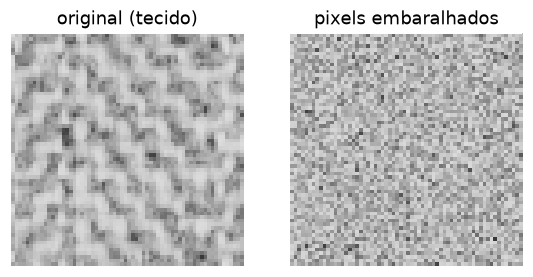

1ª ordem após quantização em 32 níveis (média, desvio, entropia)
original:    [21.677  3.496  3.686]
embaralhada: [21.677  3.496  3.686]


In [3]:
def first_order(img, levels=LEVELS):
    q = quantize(img, levels)
    p = np.bincount(q.ravel(), minlength=levels) / q.size
    i = np.arange(levels)
    mu  = (i * p).sum()
    sd  = np.sqrt((((i - mu)**2) * p).sum())
    nz  = p[p > 0]
    ent = -(nz * np.log2(nz)).sum()
    return np.array([mu, sd, ent])

sample = patches[labels == classes.index("tecido")][0]
shuffled = rng.permutation(sample.ravel()).reshape(sample.shape)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for a, im, t in zip(ax, [sample, shuffled], ["original (tecido)", "pixels embaralhados"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.show()
print("1ª ordem após quantização em 32 níveis (média, desvio, entropia)")
print("original:   ", first_order(sample).round(3))
print("embaralhada:", first_order(shuffled).round(3))

Resumo de 1ª ordem por classe (média ± desvio entre os patches; média e desvio em níveis quantizados, 0 a 31; entropia em bits):

In [4]:
F1 = np.array([first_order(p) for p in patches])
print(f"{'classe':8s} {'média (0-31)':>16s} {'desvio (níveis)':>16s} {'entropia (bits)':>16s}")
for k, name in enumerate(classes):
    m, s = F1[labels == k].mean(0), F1[labels == k].std(0)
    print(f"{name:8s} " + " ".join(f"{m[j]:9.2f} ± {s[j]:4.2f}" for j in range(3)))

classe       média (0-31)  desvio (níveis)  entropia (bits)
grama        15.80 ± 1.31      6.40 ± 0.35      4.61 ± 0.05
madeira      22.00 ± 0.82      3.03 ± 0.30      3.24 ± 0.22
tecido       21.43 ± 0.36      3.54 ± 0.17      3.71 ± 0.07
tijolo       19.59 ± 1.28      3.59 ± 0.44      3.52 ± 0.17


**Resultados**

- Patch de tecido, (média, desvio, entropia): original 21.677 / 3.496 / 3.686; embaralhado 21.677 / 3.496 / 3.686.
- Média por classe (grama, madeira, tecido, tijolo): 15.80 ± 1.31; 22.00 ± 0.82; 21.43 ± 0.36; 19.59 ± 1.28.
- Desvio por classe: 6.40 ± 0.35; 3.03 ± 0.30; 3.54 ± 0.17; 3.59 ± 0.44.
- Entropia por classe: 4.61 ± 0.05; 3.24 ± 0.22; 3.71 ± 0.07; 3.52 ± 0.17.

**Interpretação.** O embaralhamento deixou média, desvio e entropia exatamente iguais (21.677; 3.496; 3.686). Isso mostra que a 1ª ordem só enxerga o histograma e não a posição dos pixels: um patch de tecido e uma nuvem de ruído com os mesmos tons são indistinguíveis para ela. Entre as classes, a grama se destaca: desvio de 6.40 e entropia de 4.61, contra 3.03 a 3.59 e 3.24 a 3.71 nas outras três, ou seja, a grama usa uma faixa de tons bem mais larga. Madeira, tecido e tijolo ficam próximas: os desvios de tecido e tijolo (3.54 ± 0.17 e 3.59 ± 0.44) são praticamente iguais, e as médias de madeira e tecido (22.00 ± 0.82 e 21.43 ± 0.36) diferem menos que um desvio. Observamos, então, que a 1ª ordem separa bem a grama e só em parte as outras três.

## 7. Prática: GLCM manual vs. scikit-image

Implementação manual com NumPy: comparamos a imagem com ela mesma deslocada em $(dy, dx)$ e contamos os pares $(i,j)$ com `np.add.at`. Depois simetrizamos e normalizamos. Convenção de ângulos igual à do scikit-image (linhas crescem para baixo): 0° → vizinho à direita; 90° → vizinho abaixo.

In [5]:
def glcm_manual(img_q, distance, angle, levels=LEVELS, symmetric=True, normed=True):
    dy = int(round(np.sin(angle) * distance))      # mesma regra de arredondamento do scikit-image
    dx = int(round(np.cos(angle) * distance))
    h, w = img_q.shape
    r0, r1 = max(0, -dy), h - max(0, dy)           # região onde pixel e vizinho existem
    c0, c1 = max(0, -dx), w - max(0, dx)
    a = img_q[r0:r1, c0:c1]
    b = img_q[r0+dy:r1+dy, c0+dx:c1+dx]
    G = np.zeros((levels, levels))
    np.add.at(G, (a.ravel(), b.ravel()), 1)
    if symmetric: G = G + G.T
    if normed:    G = G / G.sum()
    return G

# Exemplo mínimo: imagem 4x4 com 4 níveis
mini = np.array([[0,0,1,1],
                 [0,0,1,1],
                 [0,2,2,2],
                 [2,2,3,3]], dtype=np.uint8)
print("Imagem 4x4:\n", mini)
print("\nGLCM (d=1, 0°, sem simetria nem normalização), 4 níveis:")
print(glcm_manual(mini, 1, 0, levels=4, symmetric=False, normed=False).astype(int))

Imagem 4x4:
 [[0 0 1 1]
 [0 0 1 1]
 [0 2 2 2]
 [2 2 3 3]]

GLCM (d=1, 0°, sem simetria nem normalização), 4 níveis:
[[2 2 1 0]
 [0 2 0 0]
 [0 0 3 1]
 [0 0 0 1]]


Validação contra `skimage.feature.graycomatrix` em todas as combinações de distância e ângulo, sobre o primeiro patch de grama:

In [6]:
q = quantize(patches[0])
lib = graycomatrix(q, DISTANCES, ANGLES, levels=LEVELS, symmetric=True, normed=True)

max_diff = max(np.abs(glcm_manual(q, d, a) - lib[:, :, di, ai]).max()
               for di, d in enumerate(DISTANCES) for ai, a in enumerate(ANGLES))
print("Maior diferença absoluta manual vs. scikit-image:", max_diff)
assert max_diff < 1e-12

Maior diferença absoluta manual vs. scikit-image: 0.0


Medidas de Haralick implementadas manualmente, comparadas com `graycoprops`:

In [7]:
def haralick_manual(P):
    L = P.shape[0]
    i, j = np.indices((L, L))
    mu_i, mu_j = (i*P).sum(), (j*P).sum()
    sd_i = np.sqrt((((i - mu_i)**2) * P).sum())
    sd_j = np.sqrt((((j - mu_j)**2) * P).sum())
    corr = ((i - mu_i) * (j - mu_j) * P).sum() / (sd_i * sd_j) if sd_i * sd_j > 0 else 1.0
    return {
        "contrast":      (((i - j)**2) * P).sum(),
        "dissimilarity": (np.abs(i - j) * P).sum(),
        "homogeneity":   (P / (1 + (i - j)**2)).sum(),
        "energy":        np.sqrt((P**2).sum()),
        "correlation":   corr,
    }

man = haralick_manual(glcm_manual(q, 1, 0))
G1 = graycomatrix(q, [1], [0], levels=LEVELS, symmetric=True, normed=True)
print(f"{'medida':14s} {'manual':>10s} {'skimage':>10s}   (primeiro patch de grama, d=1, 0°)")
for p in PROPS:
    lib_val = graycoprops(G1, p)[0, 0]
    print(f"{p:14s} {man[p]:10.5f} {lib_val:10.5f}")
    assert abs(man[p] - lib_val) < 1e-9

medida             manual    skimage   (primeiro patch de grama, d=1, 0°)
contrast         40.73413   40.73413
dissimilarity     4.98016    4.98016
homogeneity       0.20006    0.20006
energy            0.04881    0.04881
correlation       0.55075    0.55075


GLCM do primeiro patch de cada classe (d=1, 0°), com a fração dos pares a até 2 níveis da diagonal ($|i-j| \le 2$):

Fração dos pares com |i-j| <= 2 (d=1, 0°):
  grama    0.346
  madeira  0.697
  tecido   0.672
  tijolo   0.684


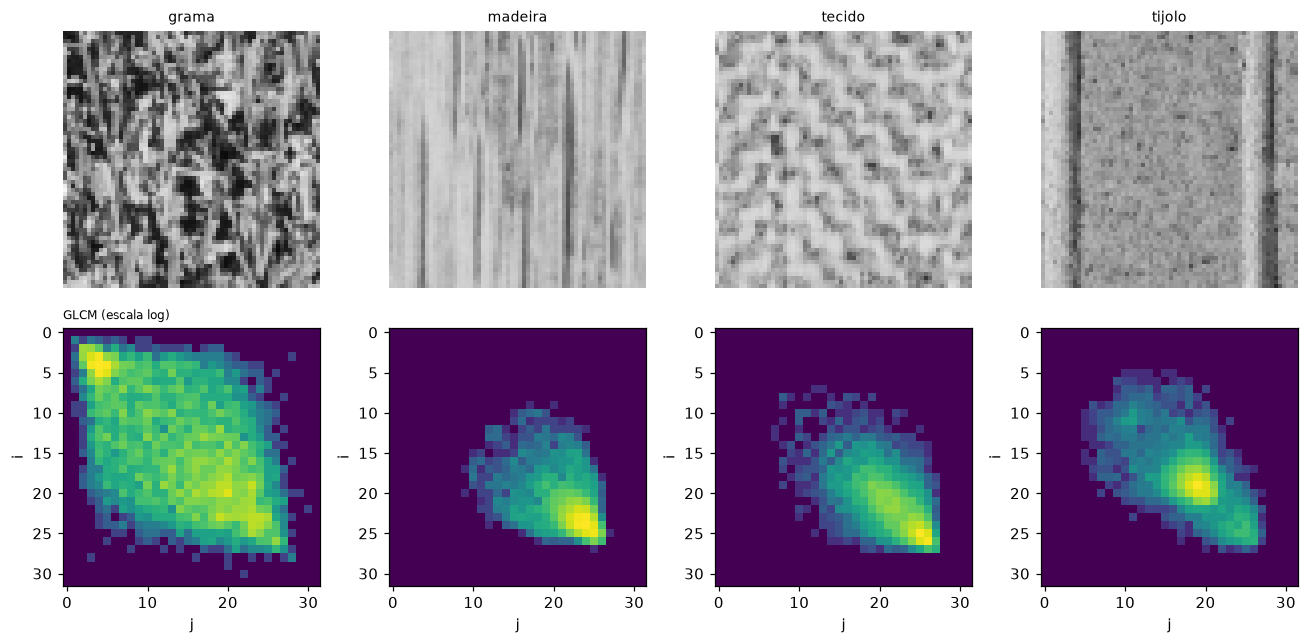

In [8]:
fig, axs = plt.subplots(2, len(classes), figsize=(3*len(classes), 6))
ii, jj = np.indices((LEVELS, LEVELS))
print("Fração dos pares com |i-j| <= 2 (d=1, 0°):")
for k, name in enumerate(classes):
    i = np.where(labels == k)[0][0]
    G = glcm_manual(quantize(patches[i]), 1, 0)
    axs[0, k].imshow(patches[i], cmap="gray", vmin=0, vmax=255); axs[0, k].set_title(name, fontsize=9); axs[0, k].axis("off")
    axs[1, k].imshow(np.log1p(G * 1e4), cmap="viridis"); axs[1, k].set_xlabel("j"); axs[1, k].set_ylabel("i")
    print(f"  {name:8s} {G[np.abs(ii - jj) <= 2].sum():.3f}")
axs[1, 0].set_title("GLCM (escala log)", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

**Resultados (seção 7)**

- Maior diferença absoluta entre a GLCM manual e a do scikit-image: 0.0.
- Primeiro patch de grama, d=1, 0° (manual = skimage): contraste 40.73413; dissimilaridade 4.98016; homogeneidade 0.20006; energia 0.04881; correlação 0.55075.
- Fração dos pares com |i-j| ≤ 2, no primeiro patch (grama, madeira, tecido, tijolo): 0.346; 0.697; 0.672; 0.684.

**Interpretação.** A GLCM manual reproduz a do scikit-image (diferença máxima de 0.0) e as cinco medidas coincidem até a 5ª casa decimal. Por isso usamos `graycomatrix` e `graycoprops` no resto do notebook sabendo que fazem o mesmo que o nosso código. Nas GLCMs mostradas, a grama é a única cujos pares se espalham longe da diagonal: só 0.346 dos pares do primeiro patch ficam a até 2 níveis da diagonal, contra 0.697 (madeira), 0.672 (tecido) e 0.684 (tijolo). Na grama, portanto, pixels vizinhos costumam ter tons bem diferentes, o que combina com o desvio mais alto da seção 6 (6.40). Esses valores vêm de um único patch por classe, então servem como ilustração e não como comparação estatística.

## 8. Prática: medidas por classe

As 5 medidas para todos os patches, em todas as distâncias e ângulos (3 × 4 × 5 = 60 valores por patch). Para comparar classes usamos a **média dos 4 ângulos**.

In [9]:
def glcm_features(img):
    G = graycomatrix(quantize(img), DISTANCES, ANGLES, levels=LEVELS, symmetric=True, normed=True)
    return np.stack([graycoprops(G, p) for p in PROPS])        # (medidas, distâncias, ângulos)

F = np.array([glcm_features(p) for p in patches])              # (patches, 5, 3, 4)
F_avg = F.mean(axis=3)                                          # média dos ângulos: (patches, 5, 3)
print("Tensor de características:", F.shape, "= (patches, medidas, distâncias, ângulos)")

print("\nMédia ± desvio por classe (d=1, média dos 4 ângulos)")
print(f"{'classe':8s}" + "".join(f"{p:>18s}" for p in PROPS))
for k, name in enumerate(classes):
    sel = F_avg[labels == k, :, 0]
    print(f"{name:8s}" + "".join(f"{sel[:, j].mean():10.3f}±{sel[:, j].std():5.3f}" for j in range(5)))

Tensor de características: (224, 5, 3, 4) = (patches, medidas, distâncias, ângulos)

Média ± desvio por classe (d=1, média dos 4 ângulos)
classe            contrast     dissimilarity       homogeneity            energy       correlation
grama       27.812±6.437     3.996±0.464     0.243±0.019     0.055±0.004     0.664±0.056
madeira      6.673±1.217     1.612±0.175     0.532±0.036     0.191±0.033     0.638±0.047
tecido       9.531±1.045     2.287±0.126     0.370±0.014     0.108±0.006     0.621±0.017
tijolo       6.303±0.906     1.712±0.140     0.465±0.026     0.154±0.020     0.748±0.050


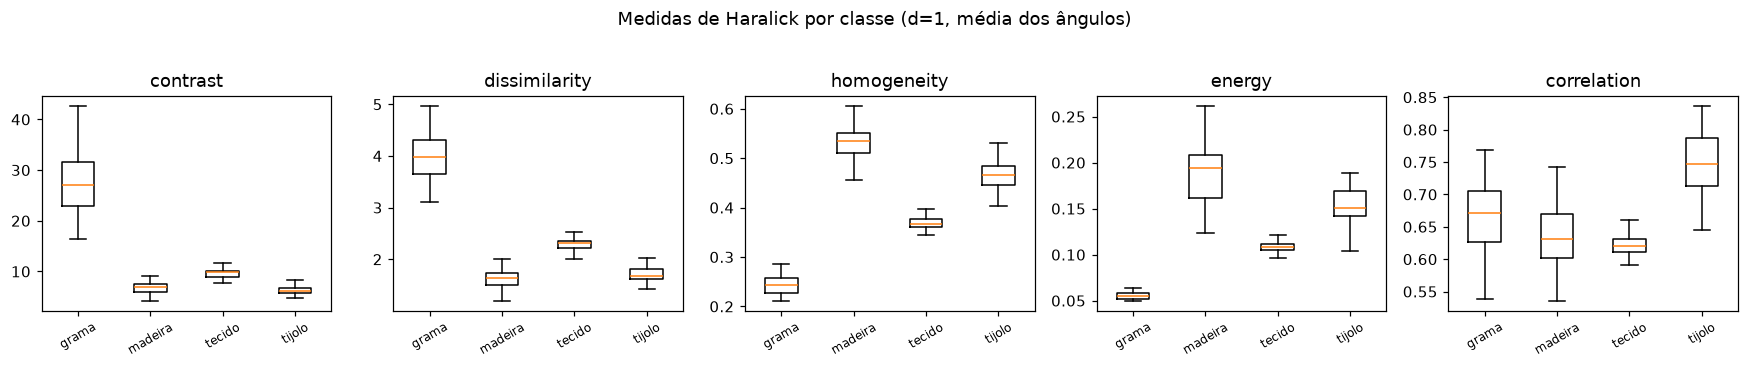

In [10]:
fig, axs = plt.subplots(1, 5, figsize=(16, 3.2))
for j, p in enumerate(PROPS):
    axs[j].boxplot([F_avg[labels == k, j, 0] for k in range(len(classes))], showfliers=False)
    axs[j].set_xticks(range(1, len(classes) + 1)); axs[j].set_xticklabels(classes, rotation=30, fontsize=8)
    axs[j].set_title(p)
fig.suptitle("Medidas de Haralick por classe (d=1, média dos ângulos)", y=1.03)
plt.tight_layout(); plt.show()

**Resultados** — média ± desvio entre patches, d=1, média dos 4 ângulos:

| Classe | contraste | dissimilaridade | homogeneidade | energia | correlação |
|---|---|---|---|---|---|
| grama | 27.812±6.437 | 3.996±0.464 | 0.243±0.019 | 0.055±0.004 | 0.664±0.056 |
| madeira | 6.673±1.217 | 1.612±0.175 | 0.532±0.036 | 0.191±0.033 | 0.638±0.047 |
| tecido | 9.531±1.045 | 2.287±0.126 | 0.370±0.014 | 0.108±0.006 | 0.621±0.017 |
| tijolo | 6.303±0.906 | 1.712±0.140 | 0.465±0.026 | 0.154±0.020 | 0.748±0.050 |

A grama tem o maior contraste (27.812) e a maior dissimilaridade (3.996), e a menor homogeneidade (0.243) e a menor energia (0.055): vizinhos com tons muito diferentes e muitos pares (i, j) distintos, nenhum dominante. A madeira é o oposto: maior homogeneidade (0.532) e maior energia (0.191), com contraste baixo (6.673), isto é, poucos pares concentrados perto da diagonal. O tijolo tem o menor contraste (6.303) e a maior correlação (0.748), e o tecido fica no meio no contraste (9.531) com a menor correlação (0.621).

Madeira e tijolo quase coincidem em contraste (6.673 ± 1.217 e 6.303 ± 0.906, diferença menor que um desvio), então o contraste sozinho não as separa. A homogeneidade (0.532 ± 0.036 contra 0.465 ± 0.026) e a correlação (0.638 ± 0.047 contra 0.748 ± 0.050) diferem cerca de dois desvios. Concluímos que nenhuma medida isolada separa as quatro classes: contraste, dissimilaridade, homogeneidade e energia distinguem a grama das demais, mas separar madeira, tecido e tijolo depende de combinar medidas.

## 9. Prática: efeito da distância e do ângulo

Medidas em função da distância $d$ (média dos 4 ângulos) e do ângulo $\theta$.

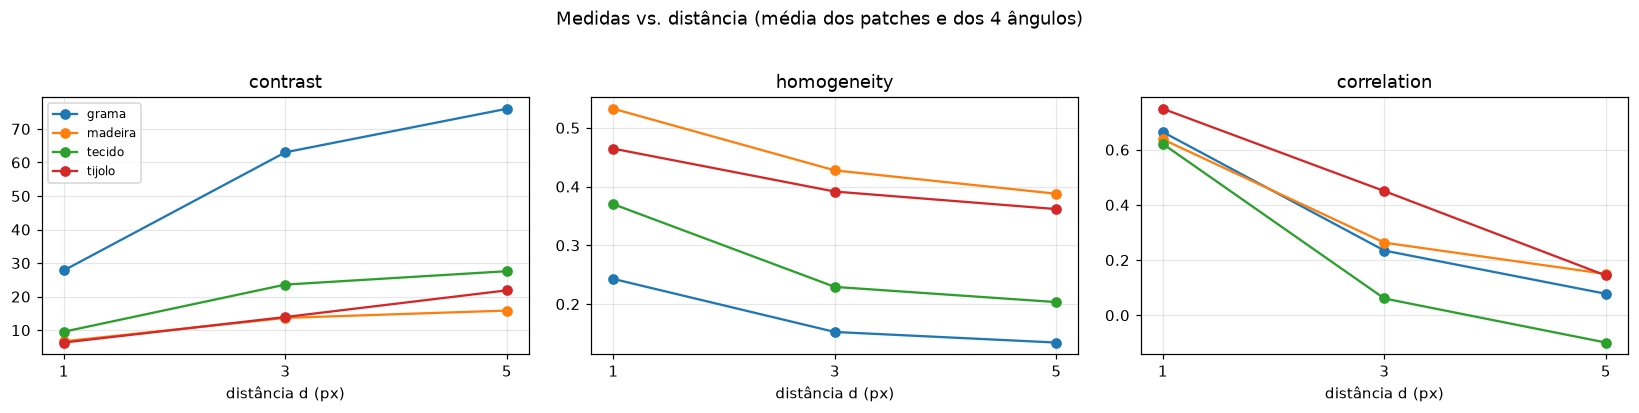

Valores médios por classe e distância (média dos patches e dos 4 ângulos):

contrast
classe        d=1      d=3      d=5
grama      27.812   63.031   76.012
madeira     6.673   13.658   15.837
tecido      9.531   23.587   27.578
tijolo      6.303   13.915   21.869

homogeneity
classe        d=1      d=3      d=5
grama       0.243    0.152    0.134
madeira     0.532    0.428    0.388
tecido      0.370    0.229    0.203
tijolo      0.465    0.392    0.362

correlation
classe        d=1      d=3      d=5
grama       0.664    0.235    0.078
madeira     0.638    0.263    0.150
tecido      0.621    0.061   -0.099
tijolo      0.748    0.450    0.144


In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (pi, p) in zip(axs, [(0, "contrast"), (2, "homogeneity"), (4, "correlation")]):
    for k, name in enumerate(classes):
        ax.plot(DISTANCES, F_avg[labels == k, pi, :].mean(0), marker="o", label=name)
    ax.set_xticks(DISTANCES); ax.set_xlabel("distância d (px)"); ax.set_title(p); ax.grid(alpha=.3)
axs[0].legend(fontsize=8)
fig.suptitle("Medidas vs. distância (média dos patches e dos 4 ângulos)", y=1.03)
plt.tight_layout(); plt.show()

print("Valores médios por classe e distância (média dos patches e dos 4 ângulos):")
for pi, p in [(0, "contrast"), (2, "homogeneity"), (4, "correlation")]:
    print(f"\n{p}")
    print(f"{'classe':8s}" + "".join(f"{'d='+str(d):>9s}" for d in DISTANCES))
    for k, name in enumerate(classes):
        print(f"{name:8s}" + "".join(f"{v:9.3f}" for v in F_avg[labels == k, pi, :].mean(0)))

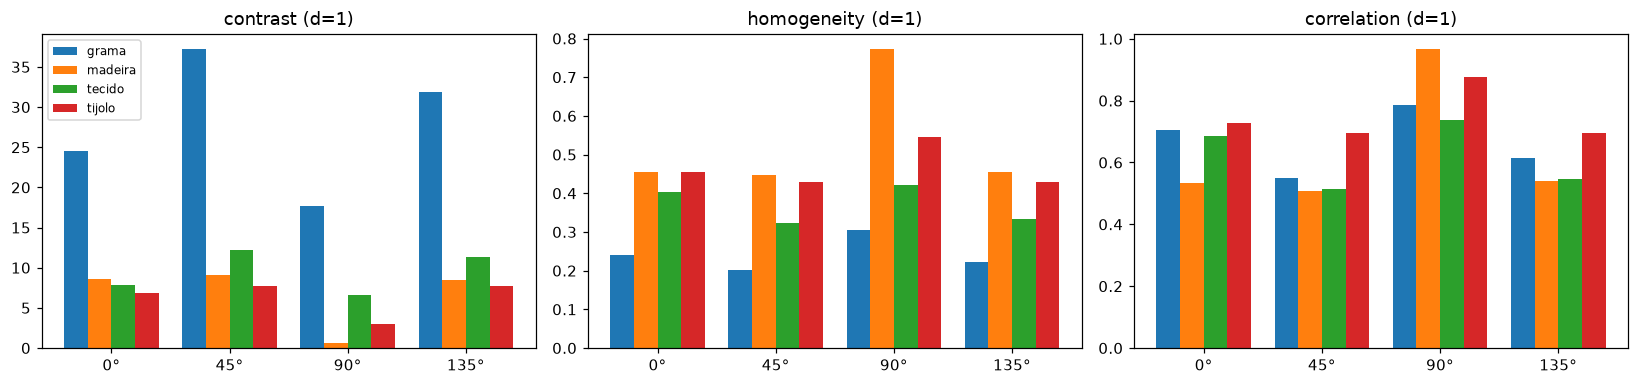

Contraste médio por ângulo e desvio/média entre os 4 ângulos:
classe    d       0°      45°      90°     135°  desv/média
grama     1    24.50   37.22   17.65   31.88       0.266
grama     3    67.17   65.83   59.30   59.82       0.056
grama     5    78.32   78.28   72.48   74.96       0.032
madeira   1     8.60    9.06    0.61    8.42       0.526
madeira   3    19.37   17.01    1.76   16.48       0.509
madeira   5    20.16   20.14    2.92   20.13       0.471
tecido    1     7.88   12.23    6.62   11.39       0.246
tecido    3    24.00   24.20   23.40   22.75       0.024
tecido    5    28.99   26.37   29.41   25.54       0.060
tijolo    1     6.85    7.69    3.01    7.67       0.306
tijolo    3    20.48   14.79    5.76   14.64       0.379
tijolo    5    28.68   26.19    6.47   26.13       0.409


In [12]:
# Nota: em 45° e 135° com d=1 o vizinho está em (1, 1), a √2 ≈ 1.41 pixel (em 0° e 90° está a 1 pixel).
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
w = 0.8 / len(classes)
for ax, (pi, p) in zip(axs, [(0, "contrast"), (2, "homogeneity"), (4, "correlation")]):
    for k, name in enumerate(classes):
        ax.bar(np.arange(4) + k*w, F[labels == k, pi, 0, :].mean(0), width=w, label=name)
    ax.set_xticks(np.arange(4) + 0.4 - w/2); ax.set_xticklabels([f"{a}°" for a in ANGLE_DEG]); ax.set_title(p + " (d=1)")
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Contraste médio por ângulo e desvio/média entre os 4 ângulos:")
print(f"{'classe':8s} {'d':>2s} {'0°':>8s} {'45°':>8s} {'90°':>8s} {'135°':>8s} {'desv/média':>11s}")
for k, name in enumerate(classes):
    for di, d in enumerate(DISTANCES):
        v = F[labels == k, 0, di, :].mean(0)
        print(f"{name:8s} {d:>2d} " + "".join(f"{x:8.2f}" for x in v) + f" {v.std() / v.mean():11.3f}")

**Resultados**

- Contraste médio em d=1 / 3 / 5: grama 27.812 / 63.031 / 76.012; madeira 6.673 / 13.658 / 15.837; tecido 9.531 / 23.587 / 27.578; tijolo 6.303 / 13.915 / 21.869.
- Homogeneidade em d=1 / 3 / 5: grama 0.243 / 0.152 / 0.134; madeira 0.532 / 0.428 / 0.388; tecido 0.370 / 0.229 / 0.203; tijolo 0.465 / 0.392 / 0.362.
- Correlação em d=1 / 3 / 5: grama 0.664 / 0.235 / 0.078; madeira 0.638 / 0.263 / 0.150; tecido 0.621 / 0.061 / -0.099; tijolo 0.748 / 0.450 / 0.144.
- Contraste em d=1 por ângulo (0° / 45° / 90° / 135°): grama 24.50 / 37.22 / 17.65 / 31.88; madeira 8.60 / 9.06 / 0.61 / 8.42; tecido 7.88 / 12.23 / 6.62 / 11.39; tijolo 6.85 / 7.69 / 3.01 / 7.67.
- Desv/média do contraste entre os ângulos em d=1 / 3 / 5: grama 0.266 / 0.056 / 0.032; madeira 0.526 / 0.509 / 0.471; tecido 0.246 / 0.024 / 0.060; tijolo 0.306 / 0.379 / 0.409.


*Distância*: Nas quatro classes o contraste cresce e a homogeneidade cai de d=1 para d=5 (grama: contraste 27.812 → 63.031 → 76.012; homogeneidade 0.243 → 0.152 → 0.134), e a correlação despenca (grama: 0.664 → 0.235 → 0.078). Ou seja, o tom de um pixel deixa de prever o tom do vizinho em poucos pixels. O aumento do contraste desacelera na grama (o ganho de d=3 para d=5 é menor que o de d=1 para d=3), enquanto o tijolo ainda cresce bastante de d=3 para d=5 (13.915 → 21.869) e a madeira quase estabiliza (13.658 → 15.837). A correlação do tecido fica negativa em d=5 (-0.099), a única negativa. Isso é compatível com um padrão que se repete, em que o tom a 5 pixels tende a ficar do lado oposto da média, mas com só três distâncias não conseguimos confirmar o período.

*Ângulo*: Madeira e tijolo são direcionais: o contraste a 90° é muito menor que nos outros ângulos (madeira em d=1: 0.61 contra 8.60, 9.06 e 8.42; tijolo em d=5: 6.47 contra 28.68, 26.19 e 26.13). Na vertical o tom quase não muda, o que combina com as fibras da madeira e os tijolos e juntas alinhados na vertical nas imagens; na horizontal os pares cruzam fibras e juntas. A razão desvio/média confirma: 0.526, 0.509 e 0.471 na madeira e 0.306, 0.379 e 0.409 no tijolo. No tijolo a anisotropia cresce com a distância porque o contraste a 90° quase não sobe (3.01 → 5.76 → 6.47), enquanto o de 0° vai de 6.85 a 28.68. Grama e tecido só parecem isotrópicas em escalas maiores: a razão cai de 0.266 (d=1) para 0.056 e 0.032 na grama, e de 0.246 para 0.024 e 0.060 no tecido.

*Diagonais*: Parte da variação em d=1 vem da geometria: em 45° e 135° o vizinho está a √2 pixel, e não a 1. O contraste das diagonais ficou acima do de 90° nas quatro classes e acima do de 0° em grama (37.22 e 31.88 contra 24.50), tecido (12.23 e 11.39 contra 7.88) e tijolo (7.69 e 7.67 contra 6.85). Por isso a razão 0.266 da grama em d=1 não deve ser lida como direção preferida da textura sem descontar esse efeito; em d=3 e d=5 ela cai para 0.056 e 0.032.

*Consequência*: A média dos quatro ângulos usada nas seções 8 e 10 mistura a direção real da textura com esse efeito geométrico e dilui a assinatura direcional da madeira e do tijolo (contraste a 90° de 0.61 e 3.01 em d=1). Isso reaparece nos resultados do k-NN.

## 10. Prática: classificação com k-vizinhos mais próximos

k-NN com k = 5; as características são padronizadas (`StandardScaler`) dentro de um `Pipeline`, ajustado só com os dados de treino. Três conjuntos de características:

1. **1ª ordem** (média, desvio, entropia): 3 características;
2. **GLCM, média dos ângulos**: 5 medidas × 3 distâncias = 15 características;
3. **GLCM completa**: 60 características.

Duas avaliações:

- **(A)** validação cruzada estratificada de 5 partições, com patches sorteados aleatoriamente entre treino e teste;
- **(B)** separação espacial: treino nas linhas 0–2 da grade de patches e teste nas linhas 4–6, **descartando a linha 3**, e também o inverso (treino nas linhas 4–6, teste nas linhas 0–2).

**Diferença entre A e B.** Todos os patches de uma classe vêm da mesma fotografia. Na validação cruzada (A), os patches de teste são sorteados no meio dos de treino, então quase todo patch de teste tem vizinhos imediatos no treino, com a mesma iluminação, as mesmas manchas e a mesma estrutura local. O k-NN pode acertar por "reconhecer a região" e não só a textura, o que tende a deixar a acurácia otimista. Em B o teste é feito em uma região que o classificador não viu, separada do treino por uma linha de patches descartada (64 pixels), e invertemos os sentidos para não depender de um lado só da imagem. Assim, A mede o acerto quando o classificador já viu vizinhos do patch testado, e B mede se as medidas generalizam para outra parte da mesma textura.

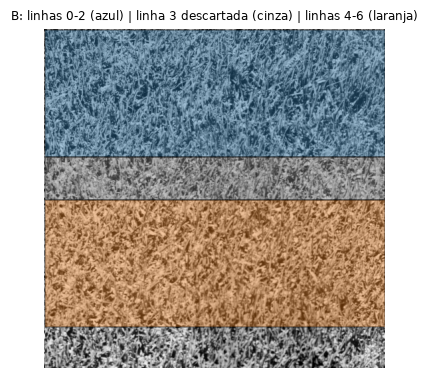

In [13]:
# Esquema da separação espacial (exemplo na imagem de grama)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(images["grama"], cmap="gray", vmin=0, vmax=255)
for y0, y1, cor in [(0, 192, "tab:blue"), (192, 256, "gray"), (256, 448, "tab:orange")]:
    ax.add_patch(Rectangle((0, y0), 512, y1 - y0, facecolor=cor, alpha=0.35, edgecolor="k", lw=1))
ax.set_title("B: linhas 0-2 (azul) | linha 3 descartada (cinza) | linhas 4-6 (laranja)", fontsize=8); ax.axis("off")
plt.show()

In [14]:
sets = {
    "1ª ordem (3)":                 F1,
    "GLCM, média dos ângulos (15)": F_avg.reshape(len(F_avg), -1),
    "GLCM completa (60)":           F.reshape(len(F), -1),
}
clf = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

# (A) validação cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pred_A = {nome: cross_val_predict(clf, X, labels, cv=cv) for nome, X in sets.items()}

# (B) separação espacial por linhas da grade de patches
def separacao_espacial(X, linhas_treino, linhas_teste):
    tr, te = np.isin(prow, linhas_treino), np.isin(prow, linhas_teste)
    pred = clone(clf).fit(X[tr], labels[tr]).predict(X[te])
    return labels[te], pred

LINHAS_CIMA, LINHAS_BAIXO = [0, 1, 2], [4, 5, 6]               # a linha 3 é descartada
res_B = {}
for nome, X in sets.items():
    y1, p1 = separacao_espacial(X, LINHAS_CIMA, LINHAS_BAIXO)   # treina em cima, testa embaixo
    y2, p2 = separacao_espacial(X, LINHAS_BAIXO, LINHAS_CIMA)   # treina embaixo, testa em cima
    res_B[nome] = (y1, p1, y2, p2)

tamanhos_A = sorted({(len(tr), len(te)) for tr, te in cv.split(F1, labels)})
print("Patches treino/teste. A (por partição):", ", ".join(f"{a}/{b}" for a, b in tamanhos_A),
      "| B:", f"{np.isin(prow, LINHAS_CIMA).sum()}/{np.isin(prow, LINHAS_BAIXO).sum()}\n")
print(f"{'conjunto de características':32s} {'A: CV':>7s} {'B cima>baixo':>13s} {'B baixo>cima':>13s} {'B (2 sentidos)':>15s}")
for nome in sets:
    y1, p1, y2, p2 = res_B[nome]
    print(f"{nome:32s} {accuracy_score(labels, pred_A[nome]):7.3f} {accuracy_score(y1, p1):13.3f} {accuracy_score(y2, p2):13.3f} "
          f"{accuracy_score(np.concatenate([y1, y2]), np.concatenate([p1, p2])):15.3f}")

Patches treino/teste. A (por partição): 179/45, 180/44 | B: 96/96

conjunto de características        A: CV  B cima>baixo  B baixo>cima  B (2 sentidos)
1ª ordem (3)                       0.929         0.885         0.760           0.823
GLCM, média dos ângulos (15)       0.982         0.896         0.938           0.917
GLCM completa (60)                 1.000         0.969         0.990           0.979


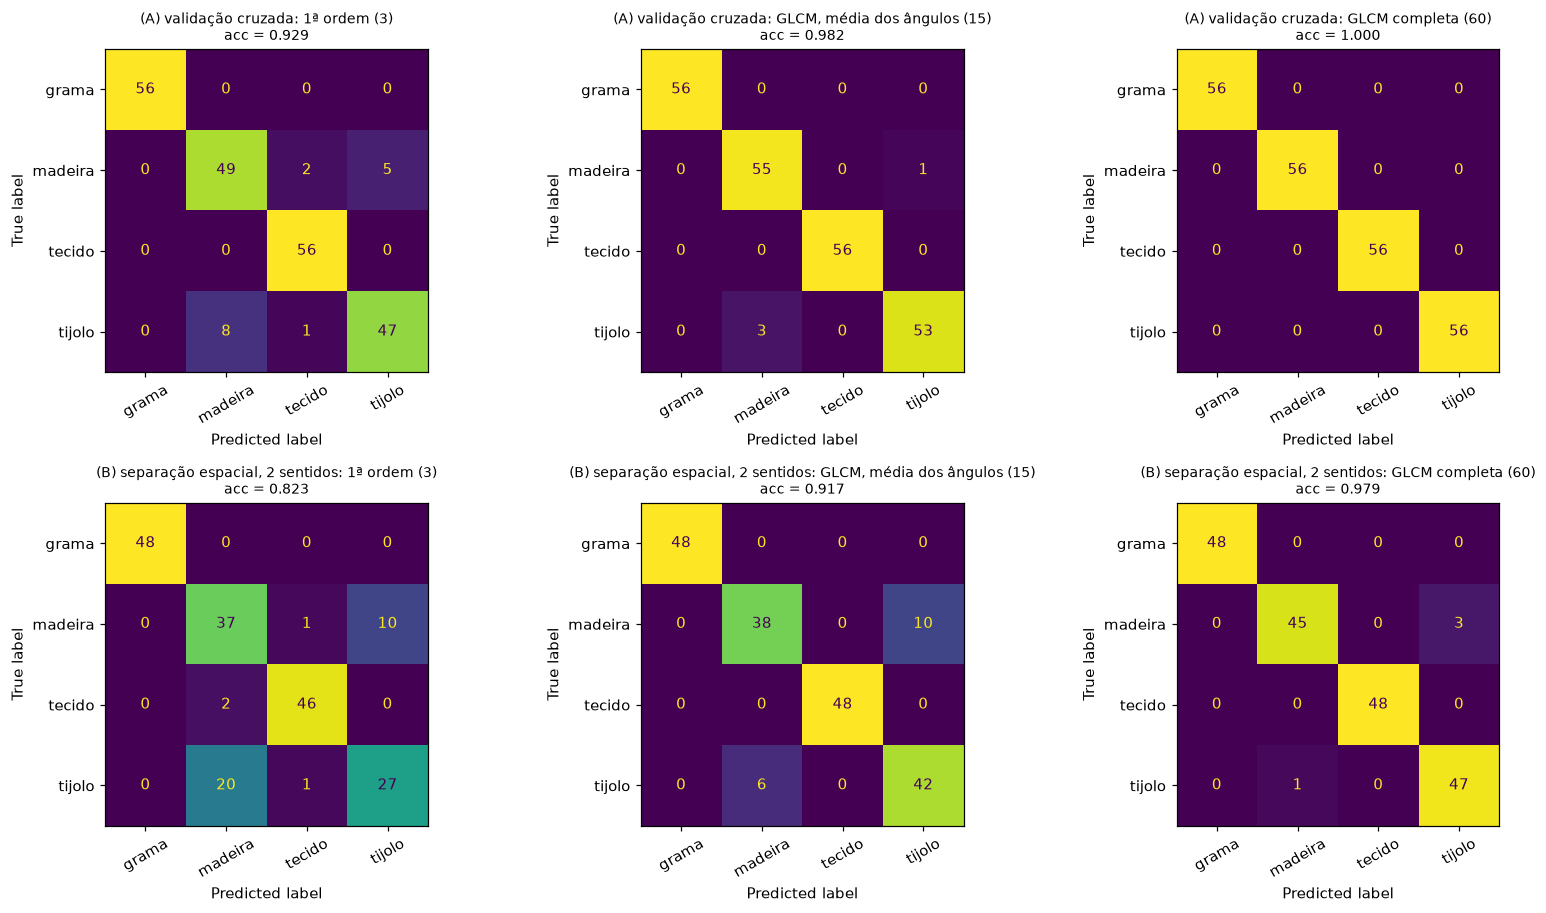

In [15]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8.4))
for ax, nome in zip(axs[0], sets):
    ConfusionMatrixDisplay(confusion_matrix(labels, pred_A[nome]), display_labels=classes).plot(ax=ax, colorbar=False, xticks_rotation=30)
    ax.set_title(f"(A) validação cruzada: {nome}\nacc = {accuracy_score(labels, pred_A[nome]):.3f}", fontsize=9)
for ax, nome in zip(axs[1], sets):
    y1, p1, y2, p2 = res_B[nome]
    y, pr = np.concatenate([y1, y2]), np.concatenate([p1, p2])
    ConfusionMatrixDisplay(confusion_matrix(y, pr), display_labels=classes).plot(ax=ax, colorbar=False, xticks_rotation=30)
    ax.set_title(f"(B) separação espacial, 2 sentidos: {nome}\nacc = {accuracy_score(y, pr):.3f}", fontsize=9)
plt.tight_layout(); plt.show()

**Resultados (seção 10)** — acurácia do k-NN (k = 5):

| Conjunto | A: validação cruzada | B cima→baixo | B baixo→cima | B (2 sentidos) |
|---|---|---|---|---|
| 1ª ordem (3) | 0.929 | 0.885 | 0.760 | 0.823 |
| GLCM, média dos ângulos (15) | 0.982 | 0.896 | 0.938 | 0.917 |
| GLCM completa (60) | 1.000 | 0.969 | 0.990 | 0.979 |

- Patches de treino/teste: A, 179/45 e 180/44 por partição; B, 96/96.
- As contagens de acertos e erros por classe estão nas matrizes de confusão acima.

**Interpretação.**

*Efeito da avaliação.* Todas as acurácias caem de A para B: a 1ª ordem vai de 0.929 para 0.823, a GLCM com média dos ângulos de 0.982 para 0.917 e a GLCM completa de 1.000 para 0.979. A GLCM completa quase não muda e a 1ª ordem é a que mais perde. A 1ª ordem também oscila mais entre os dois sentidos de B (0.885 e 0.760) do que a GLCM completa (0.969 e 0.990). Uma explicação provável, que não testamos neste notebook, é que média e desvio dependem do brilho da região, que varia ao longo da imagem.

*O que a GLCM acrescenta.* A ordem é a mesma em A e em B: 1ª ordem, depois GLCM com média dos ângulos, depois GLCM completa. A diferença entre a 1ª ordem e a GLCM completa é maior em B (0.823 contra 0.979) do que em A (0.929 contra 1.000).

*Quais classes se confundem.* Quase todos os erros são entre madeira e tijolo. Em B (matrizes de baixo), a 1ª ordem classificou 20 tijolos como madeira e 10 madeiras como tijolo; a GLCM com média dos ângulos, 6 e 10; a GLCM completa, 1 e 3. A grama nunca foi confundida com outra classe, em nenhum conjunto nem em A ou B. O tecido só aparece nos erros da 1ª ordem (em B, 2 tecidos classificados como madeira, 1 madeira como tecido e 1 tijolo como tecido).

*Por que madeira e tijolo.* As duas são texturas verticais (seção 9: contraste a 90° de 0.61 e 3.01 em d=1), com contraste médio quase igual (6.673 e 6.303) e, na 1ª ordem, desvios e entropias próximos (3.03 e 3.59; 3.24 e 3.52). Manter os ângulos separados preserva diferenças que a média dilui (por exemplo, 0.61 contra 3.01 a 90° em d=1): a GLCM com 15 características errou 16 patches em B, e a completa, com 60, errou 4.

## 11. Conclusões

**Resultados** — acurácia por conjunto de características (A: validação cruzada | B: separação espacial, 2 sentidos):

- 1ª ordem (3): 0.929 | 0.823
- GLCM, média dos ângulos (15): 0.982 | 0.917
- GLCM completa (60): 1.000 | 0.979

**Conclusões.**

- A 1ª ordem separa bem a grama (desvio de 6.40 e entropia de 4.61, contra no máximo 3.59 e 3.71 nas outras classes), mas ignora a organização espacial: o patch de tecido embaralhado manteve exatamente as mesmas medidas. Acurácia do k-NN: 0.929 em A e 0.823 em B.
- A GLCM e as medidas de Haralick separam melhor as classes: 0.982 (A) e 0.917 (B) com 15 características, e 1.000 (A) e 0.979 (B) com 60. Nossa GLCM manual coincidiu com a do scikit-image (diferença máxima de 0.0).
- Nenhuma medida sozinha separa as quatro classes. Contraste, dissimilaridade, homogeneidade e energia distinguem a grama das outras, mas madeira e tijolo têm contraste quase igual (6.673 e 6.303) e só se separam combinando medidas e mantendo os ângulos separados.
- A distância controla a escala: o contraste cresce e a correlação cai de d=1 para d=5 em todas as classes. O ângulo mostra a direção da textura: madeira e tijolo têm contraste muito menor a 90° (0.61 e 3.01 em d=1), e em d=1 as diagonais ficam inflacionadas pela distância de √2 pixel.
- A validação cruzada (A) deu resultados mais altos que a separação espacial (B) nos três conjuntos de características. Para comparar os conjuntos, B é a avaliação mais confiável, e nela a GLCM completa foi a melhor (0.979).
- Limitações do experimento: cada classe é uma única fotografia (56 patches por classe), então B testa outras regiões da mesma foto e não outras fotos de grama, madeira, tecido ou tijolo; e só usamos três distâncias, o que não basta para identificar o período do tecido.

## 12. Referências

1. HARALICK, R. M.; SHANMUGAM, K.; DINSTEIN, I. **Textural features for image classification.** *IEEE Transactions on Systems, Man, and Cybernetics*, v. SMC-3, n. 6, p. 610–621, 1973.
2. BRODATZ, P. **Textures: A Photographic Album for Artists and Designers.** New York: Dover, 1966.
3. GONZALEZ, R. C.; WOODS, R. E. **Digital Image Processing.** 4. ed. Pearson, 2018.
4. VAN DER WALT, S. et al. **scikit-image: image processing in Python.** *PeerJ*, v. 2, e453, 2014.
5. HARRIS, C. R. et al. **Array programming with NumPy.** *Nature*, v. 585, p. 357–362, 2020.
6. PEDREGOSA, F. et al. **Scikit-learn: machine learning in Python.** *Journal of Machine Learning Research*, v. 12, p. 2825–2830, 2011.
7. USC-SIPI Image Database, **Volume 1: Textures.** University of Southern California. Disponível em: https://sipi.usc.edu/database/. Acesso em: 26 out. 2026.
8. Documentação do scikit-image: *GLCM Texture Features* (`skimage.feature.graycomatrix` e `graycoprops`).